In [1]:
# Cell 1 - imports and device setup
import os
import re
import random
import math
import time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold

# Optional: summary
!pip install -q torchsummary
from torchsummary import summary

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Device:', device)
# Speedups
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True


Device: cpu



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Cell 2 - dataset path (use your local path)
datasetPath = r"C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\Data"  # as provided

# Validate structure: expects 4 subfolders (non_demented, mild_demented, moderate_demented, very_mild_demented)
classes = sorted([d.name for d in Path(datasetPath).iterdir() if d.is_dir()])
print('Detected classes:', classes)
for c in classes:
    n = len(list(Path(datasetPath, c).glob('*.*')))
    print(f"  {c}: {n} files")


Detected classes: ['Mild Dementia', 'Moderate Dementia', 'Non Demented', 'Very mild Dementia']
  Mild Dementia: 5002 files
  Moderate Dementia: 488 files
  Non Demented: 67222 files
  Very mild Dementia: 13725 files


In [3]:
# Cell 3 - build dataframe with filename, class_name, subject_id
def extract_subject_id(filename):
    # filenames like OAS1_0028_MR1_mpr-1_100
    # get OAS1_0028 as subject id
    m = re.match(r'([A-Za-z0-9]+_[0-9]+)', filename)
    return m.group(1) if m else filename.split('_')[0]

rows = []
for cls in classes:
    folder = Path(datasetPath) / cls
    for p in folder.glob('*'):
        if p.is_file():
            fname = p.stem  # without extension
            subj = extract_subject_id(fname)
            rows.append({'filepath': str(p), 'class_name': cls, 'subject': subj, 'fname': p.name})

df = pd.DataFrame(rows)
print('Total images:', len(df))
display(df['class_name'].value_counts())


Total images: 86437


class_name
Non Demented          67222
Very mild Dementia    13725
Mild Dementia          5002
Moderate Dementia       488
Name: count, dtype: int64

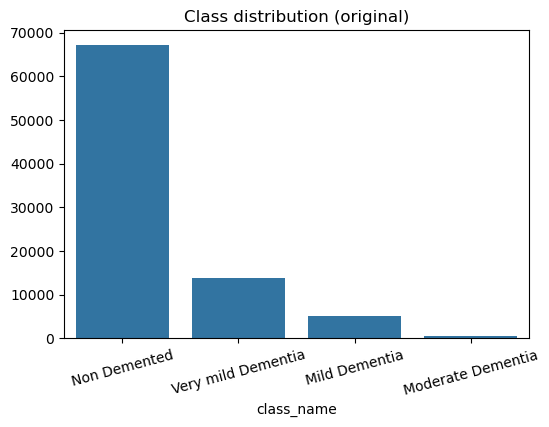

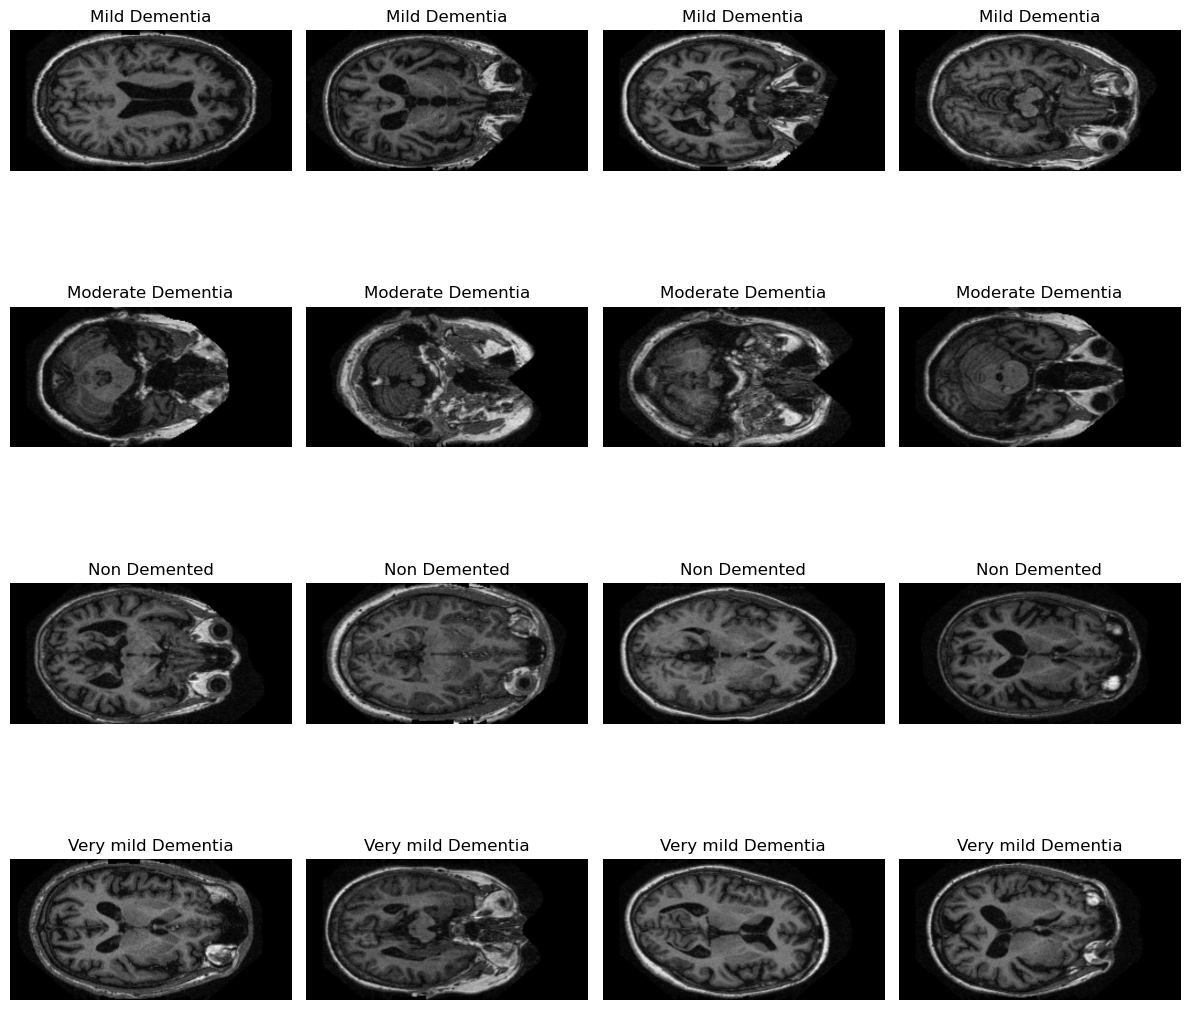

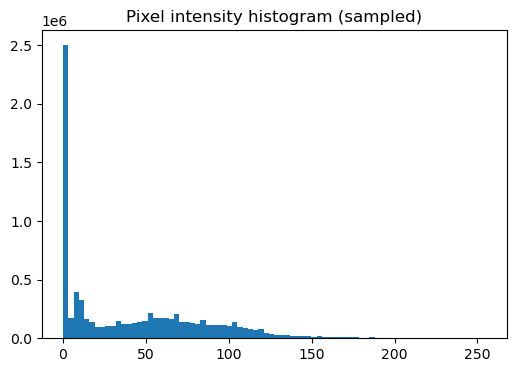

In [4]:
# Cell 4 - EDA visuals
plt.figure(figsize=(6,4))
sns.barplot(x=df['class_name'].value_counts().index, y=df['class_name'].value_counts().values)
plt.title('Class distribution (original)')
plt.xticks(rotation=15)
plt.show()

# Show example images (first 4 of each class)
fig, axs = plt.subplots(len(classes), 4, figsize=(12, 3*len(classes)))
for i, cls in enumerate(classes):
    sample = df[df['class_name']==cls].sample(min(4, len(df[df['class_name']==cls])), random_state=SEED)['filepath'].values
    for j, fp in enumerate(sample):
        img = Image.open(fp).convert('RGB')
        axs[i,j].imshow(img)
        axs[i,j].set_title(f"{cls}")
        axs[i,j].axis('off')
plt.tight_layout()
plt.show()

# Pixel intensity histogram (sample subset to save time)
sample_paths = df['filepath'].sample(min(2000, len(df)), random_state=SEED).values
pix_vals = []
for p in sample_paths:
    im = np.array(Image.open(p).convert('L').resize((64,64)))
    pix_vals.extend(im.flatten())
plt.figure(figsize=(6,4))
plt.hist(pix_vals, bins=80)
plt.title('Pixel intensity histogram (sampled)')
plt.show()


In [5]:
# Cell 5 - label encoding (one-hot later where needed)
class2idx = {c:i for i,c in enumerate(classes)}
idx2class = {i:c for c,i in class2idx.items()}
df['label'] = df['class_name'].map(class2idx)
print('Mapping:', class2idx)

# One-hot example (useful for ROC)
num_classes = len(classes)
df['onehot'] = df['label'].apply(lambda x: np.eye(num_classes,dtype=int)[x])


Mapping: {'Mild Dementia': 0, 'Moderate Dementia': 1, 'Non Demented': 2, 'Very mild Dementia': 3}


In [6]:
# Cell 6 - Dataset and transforms
IMG_SIZE = 224  # good for ResNet encoder

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),  # scales to [0,1]
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])
val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

class MRIDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df.reset_index(drop=True)
        self.transforms = transforms
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['filepath']).convert('RGB')
        if self.transforms:
            img = self.transforms(img)
        label = int(row['label'])
        return img, label, row['subject'], row['filepath']


Class counts: [ 5002   488 67222 13725]
Class weights (for loss): {0: 0.34220632681463287, 1: 3.507614849849987, 2: 0.02546362867404709, 3: 0.12471519466133286}


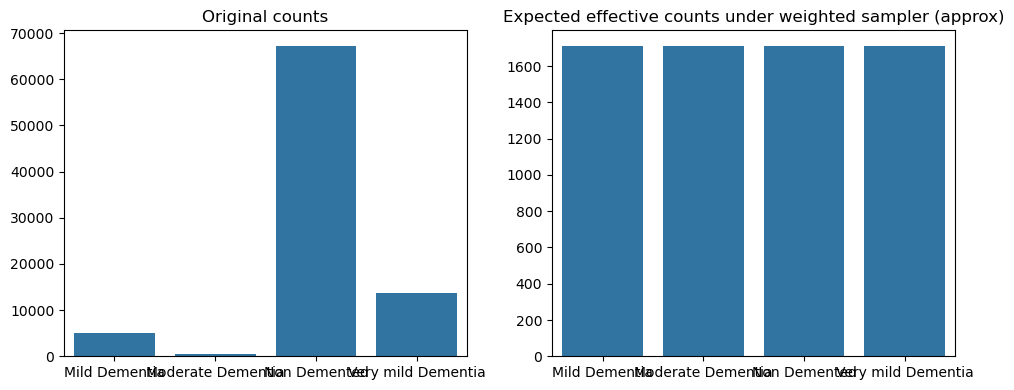

In [7]:
# Cell 7 - compute class counts, weights, sampler
counts = df['label'].value_counts().sort_index().values
print('Class counts:', counts)
class_weights = {i: 1.0/float(counts[i]) for i in range(num_classes)}
# normalize weights to sum to num_classes
total = sum(class_weights.values())
class_weights = {k: v/total * num_classes for k,v in class_weights.items()}
print('Class weights (for loss):', class_weights)

# Create sample weights per-sample for WeightedRandomSampler
sample_weights = df['label'].map(lambda x: class_weights[x]).values
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# Plot before / after approximation: original and effective sampled distribution
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.barplot(x=[idx2class[i] for i in range(num_classes)], y=counts)
plt.title('Original counts')

# approximate expected counts after weighted sampling (resample len(df))
expected = []
for i in range(num_classes):
    prob = sum(df['label'].map(lambda x: class_weights[x] if x==i else 0))/sum(sample_weights)
    # instead simpler: expected proportional to sum of weights for class_i
    expected.append(np.sum(sample_weights * (df['label']==i)))
plt.subplot(1,2,2)
sns.barplot(x=[idx2class[i] for i in range(num_classes)], y=expected)
plt.title('Expected effective counts under weighted sampler (approx)')
plt.tight_layout()
plt.show()


In [8]:
# Cell 8 - Weighted focal loss
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.reduction = reduction
    def forward(self, inputs, targets):
        # inputs: logits (batch, C)
        ce = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        loss = ((1-pt)**self.gamma) * ce
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss

# class_weights tensor for loss
w = torch.tensor([class_weights[i] for i in range(num_classes)], dtype=torch.float).to(device)
criterion = FocalLoss(gamma=2.0, weight=w)


In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models

def unet_model(input_shape=(128, 128, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(p3)
    c4 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c4)
    p4 = layers.MaxPooling2D(pool_size=(2, 2))(c4)

    # Bottleneck
    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(p4)
    c5 = layers.Conv2D(1024, (3, 3), activation='relu', padding='same')(c5)

    # Decoder (corrected channel connections)
    u6 = layers.Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = layers.concatenate([u6, c4])  # 512+512=1024
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(u6)
    c6 = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(c6)

    u7 = layers.Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = layers.concatenate([u7, c3])  # 256+256=512
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(u7)
    c7 = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(c7)

    u8 = layers.Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = layers.concatenate([u8, c2])  # 128+128=256
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(u8)
    c8 = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(c8)

    u9 = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = layers.concatenate([u9, c1])  # 64+64=128
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(u9)
    c9 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(c9)

    # Output (classification)
    outputs = layers.Conv2D(num_classes, (1, 1), activation='softmax')(c9)

    model = models.Model(inputs=[inputs], outputs=[outputs])

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Example usage:
# model = unet_model(input_shape=(128, 128, 3), num_classes=4)
# model.summary()

In [10]:
# Cell 10 - training utilities
from copy import deepcopy

def train_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    pbar = tqdm(loader, desc='Train', leave=False)
    for imgs, labels, *_ in pbar:
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(scaler is not None)):
            logits = model(imgs)
            loss = criterion(logits, labels)
        if scaler:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        preds = torch.argmax(logits, dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
        pbar.set_postfix({'loss': running_loss/total, 'acc': correct/total})
    return running_loss/total, correct/total

def val_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_logits = []
    all_labels = []
    with torch.no_grad():
        pbar = tqdm(loader, desc='Valid', leave=False)
        for imgs, labels, *_ in pbar:
            imgs = imgs.to(device, non_blocking=True)
            labels = labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            running_loss += loss.item() * imgs.size(0)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == labels).sum().item()
            total += imgs.size(0)
            all_logits.append(logits.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            pbar.set_postfix({'loss': running_loss/total, 'acc': correct/total})
    all_logits = np.concatenate(all_logits, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    return running_loss/total, correct/total, all_logits, all_labels

class EarlyStopping:
    def __init__(self, patience=6, mode='max', delta=0.0):
        self.patience = patience
        self.mode = mode
        self.delta = delta
        self.best = None
        self.counter = 0
        self.early_stop = False
    def step(self, metric):
        if self.best is None:
            self.best = metric
            return False
        if (self.mode=='max' and metric > self.best + self.delta) or (self.mode=='min' and metric < self.best - self.delta):
            self.best = metric
            self.counter = 0
            return False
        else:
            self.counter +=1
            if self.counter >= self.patience:
                self.early_stop = True
            return self.early_stop


In [11]:
# Cell 11 — Safe subject-level random split (no stratification)
from sklearn.model_selection import train_test_split
from collections import Counter

# Step 1: Build subject-level label mapping (majority label per subject)
subjects = df[['subject', 'label']].drop_duplicates()
subj_label = subjects.groupby('subject')['label'].agg(lambda x: Counter(x).most_common(1)[0][0]).reset_index()

# Step 2: Check subject counts per class
class_counts = subj_label['label'].value_counts()
print("Subject counts per class:\n", class_counts)

# Step 3: Perform random subject-level split (no stratification)
# This avoids ValueError from stratify when a class has <2 members.
subj_train, subj_temp = train_test_split(subj_label, test_size=0.30, random_state=SEED)
subj_val, subj_test = train_test_split(subj_temp, test_size=0.50, random_state=SEED)

# Step 4: Helper to map subjects to their image paths
def df_for_subjects(subj_df):
    return df[df['subject'].isin(subj_df['subject'])].reset_index(drop=True)

train_df = df_for_subjects(subj_train)
val_df   = df_for_subjects(subj_val)
test_df  = df_for_subjects(subj_test)

# Step 5: Summary
print(f"Images split → Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")
print(f"Subjects split → Train: {len(subj_train)}, Val: {len(subj_val)}, Test: {len(subj_test)}")

print("\nTrain class distribution:")
print(train_df['class_name'].value_counts())
print("\nVal class distribution:")
print(val_df['class_name'].value_counts())
print("\nTest class distribution:")
print(test_df['class_name'].value_counts())


Subject counts per class:
 label
2    266
3     58
0     21
1      2
Name: count, dtype: int64
Images split → Train: 59414, Val: 12627, Test: 14396
Subjects split → Train: 242, Val: 52, Test: 53

Train class distribution:
class_name
Non Demented          45201
Very mild Dementia    10126
Mild Dementia          3843
Moderate Dementia       244
Name: count, dtype: int64

Val class distribution:
class_name
Non Demented          10675
Very mild Dementia     1220
Mild Dementia           488
Moderate Dementia       244
Name: count, dtype: int64

Test class distribution:
class_name
Non Demented          11346
Very mild Dementia     2379
Mild Dementia           671
Name: count, dtype: int64


In [12]:
# Cell 12 - dataloaders and sampler integrated, use many workers and pin_memory
train_ds = MRIDataset(train_df, transforms=train_transforms)
val_ds = MRIDataset(val_df, transforms=val_transforms)
test_ds = MRIDataset(test_df, transforms=val_transforms)

# Sampler for training to oversample minority classes
train_sample_weights = train_df['label'].map(lambda x: class_weights[x]).values
train_sampler = WeightedRandomSampler(weights=train_sample_weights, num_samples=len(train_ds), replacement=True)

BATCH_SIZE = 32  # adjust according to GPU memory
NUM_WORKERS = min(8, os.cpu_count()//2)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

print('Batches (train,val,test):', len(train_loader), len(val_loader), len(test_loader))


Batches (train,val,test): 1857 395 450


In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50

def unet_resnet50(input_shape=(224, 224, 3), num_classes=4):
    # Load pretrained ResNet50 as encoder
    base_model = ResNet50(include_top=False, weights='imagenet', input_shape=input_shape)

    # Encoder feature maps for skip connections
    skip_connection_names = [
        "input_1",          # 224x224x3
        "conv1_relu",       # 112x112x64
        "conv2_block3_out", # 56x56x256
        "conv3_block4_out", # 28x28x512
        "conv4_block6_out"  # 14x14x1024
    ]
    encoder_output = base_model.get_layer("conv5_block3_out").output  # 7x7x2048

    # Decoder path
    x = encoder_output
    for filters, name in zip([1024, 512, 256, 128, 64], reversed(skip_connection_names[1:])):
        skip = base_model.get_layer(name).output
        x = layers.Conv2DTranspose(filters, (2, 2), strides=(2, 2), padding="same")(x)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, (3, 3), activation="relu", padding="same")(x)
        x = layers.Conv2D(filters, (3, 3), activation="relu", padding="same")(x)

    # Final upsampling to original size
    x = layers.Conv2DTranspose(64, (2, 2), strides=(2, 2), padding="same")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    outputs = layers.Conv2D(num_classes, (1, 1), activation="softmax")(x)

    # Build and compile model
    model = models.Model(inputs=base_model.input, outputs=outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])
    return model

# Example usage:
model = unet_resnet50(input_shape=(224,224,3), num_classes=4)
model.summary()


In [ ]:
# Cell 14 - evaluation on separate test set
import sklearn
all_logits = []
all_labels = []
with torch.no_grad():
    for imgs, labels, *_ in tqdm(test_loader, desc='Testing'):
        imgs = imgs.to(device)
        logits = model_best(imgs)
        all_logits.append(logits.cpu().numpy())
        all_labels.append(labels.numpy())
all_logits = np.concatenate(all_logits, axis=0)
all_labels = np.concatenate(all_labels, axis=0)
all_probs = scipy.special.softmax(all_logits, axis=1) if 'scipy' in globals() else np.exp(all_logits) / np.sum(np.exp(all_logits), axis=1, keepdims=True)
preds = np.argmax(all_probs, axis=1)
test_acc = (preds == all_labels).mean()
print('Test accuracy:', test_acc)

# Classification report
print(classification_report(all_labels, preds, target_names=classes, digits=4))

# Confusion matrix heatmap
cm = confusion_matrix(all_labels, preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix')
plt.show()

# ROC and AUC per class
from sklearn.preprocessing import label_binarize
y_true_bin = label_binarize(all_labels, classes=list(range(num_classes)))
fpr = dict(); tpr = dict(); roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8,6))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'{classes[i]} (AUC={roc_auc[i]:.3f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC Curves'); plt.legend()
plt.show()


C:\Users\sanja\anaconda3\Lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


In [ ]:
# Cell 15 - confirm saved model and print summary
print('Saved model path: best_unet_resnet34_alzheimer.pth')
# Print model summary of the loaded model
model_best = UNetResNet34Classifier(num_classes=num_classes, pretrained=False).to(device)
model_best.load_state_dict(torch.load('best_unet_resnet34_alzheimer.pth', map_location=device))
summary(model_best, (3, IMG_SIZE, IMG_SIZE))
